In [ ]:
#import libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df=pd.read_csv('/content/student_exam_data_v1.csv')
df.head()

,study_hours,exam_score
0,4.4,59
1,9.6,98
2,7.6,82
3,6.4,69
4,2.4,42


In [ ]:
df.shape

(500, 2)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   study_hours  500 non-null    float64
 1   exam_score   500 non-null    int64  
dtypes: float64(1), int64(1)
memory usage: 7.9 KB


In [ ]:
df.describe()

,study_hours,exam_score
count,500.000000,500.000000
mean,5.488600,65.182000
std,2.690369,17.950971
min,1.000000,32.000000
25%,3.200000,50.000000
50%,5.600000,66.000000
75%,7.800000,81.000000
max,9.900000,99.000000


In [ ]:
df.isnull().sum()

,0
study_hours,0
exam_score,0


In [ ]:
#convert study hours to the nearest lower integer by removing decimal values
df['study_hours']=df['study_hours'].apply(np.floor)
df.head()

,study_hours,exam_score
0,4.0,59
1,9.0,98
2,7.0,82
3,6.0,69
4,2.0,42


In [ ]:
#independent variable
x=df.drop('exam_score',axis=1)
x.head()

,study_hours
0,4.0
1,9.0
2,7.0
3,6.0
4,2.0


In [ ]:
#dependent variable
y=df['exam_score']
y.head()

,exam_score
0,59
1,98
2,82
3,69
4,42


In [ ]:
#split the dataset into training and testing
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [ ]:
#create the model
model=LinearRegression()

In [ ]:
#train the model
model.fit(x_train,y_train)
print("Model Trained")

Model Trained


In [ ]:
#Generate predictions for training and testing datasets using the trained model
y_train_pred=model.predict(x_train)
y_test_pred=model.predict(x_test)
print("Predictions generated for both training anjd testing datasets")

Predictions generated for both training anjd testing datasets


In [ ]:
#Evaluate the performance of the model by using metrics
print("Model Evaluation Metrics")
print("Mean Absolute Error(MAE):",mean_absolute_error(y_train,y_train_pred))
print("Mean Squared Error(MSE):",mean_squared_error(y_train,y_train_pred))
print("Root Mean Squared Error(RMSE):",np.sqrt(mean_squared_error(y_train,y_train_pred)))
print("R2 Score:",r2_score(y_train,y_train_pred))

Model Evaluation Metrics
Mean Absolute Error(MAE): 2.891552490317494
Mean Squared Error(MSE): 12.973348385054424
Root Mean Squared Error(RMSE): 3.601853465239032
R2 Score: 0.9600357194152515


In [ ]:
# Evaluate the performance of the model on the test dataset
print("Test Model Evaluation Metrics")
print("Mean Absolute Error(MAE):", mean_absolute_error(y_test, y_test_pred))
print("Mean Squared Error(MSE):", mean_squared_error(y_test, y_test_pred))
print("Root Mean Squared Error(RMSE):", np.sqrt(mean_squared_error(y_test, y_test_pred)))
print("R2 Score:", r2_score(y_test, y_test_pred))

In [ ]:
#intercept
print("Intercept:",model.intercept_)

Intercept: 32.50579073158705


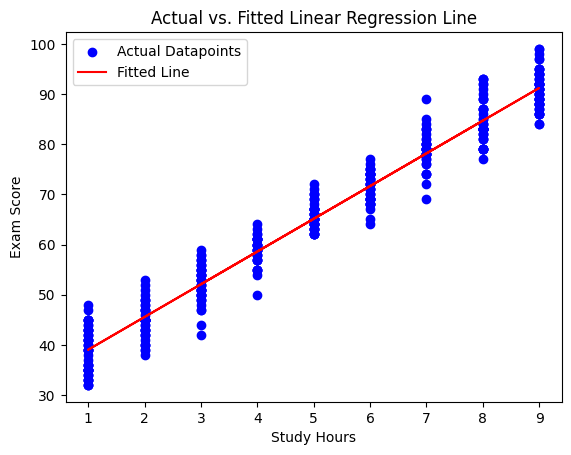

In [ ]:
#Plot actual training datapoints and fitted linear regression line for visualization
plt.scatter(x_train,y_train,color='blue',label='Actual Datapoints')
plt.plot(x_train,y_train_pred,color='red',label='Fitted Line')
plt.xlabel('Study Hours')
plt.ylabel('Exam Score')
plt.title('Actual vs. Fitted Linear Regression Line')
plt.legend()
plt.show()